# 04b — Causal Market Structure Engine & Statistical Evaluation
**Stock-Market-ML-Predictor v3**  
**Asset:** BTCUSDT | **Candle Frequency:** 5-minute  
**Dataset:** `master.csv` (TRAIN partition: 2023-11-01 to 2025-12-07, $N=220,953$ candles, 136 engineered features across 17 groups)  
**Companion File:** `drawings.csv` (role: `drawing`, 10 columns for raw price levels, targets, stops, and trigger codes)  

### Strict Safety & Hygiene Rules:
- Evaluated **exclusively on the training partition**. Validation and test partitions are strictly isolated to prevent leakage and data snooping.  
- Test split remains **100% locked**.  
- All parameters strictly bound to the **pre-declared grid in `docs/decisions.md` Section 9.1** (zero post-hoc label tuning).  
- All interpretations are **computed dynamically from data tables** (no hardcoded manual metrics, zero untyped claims).  
- **Causality contract:** Swing pivots confirmed strictly at $i+k$; levels are append-only; zero raw price levels in role `feature`.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure local src/ imports resolve cleanly
ML_DIR = Path.cwd()
if ML_DIR.name != "ML":
    ML_DIR = ML_DIR / "ML"
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

from src import config
from src.column_dictionary import load_master, get_feature_columns, get_column_role
from src.io_utils import load_drawings_csv
from src.features import FEATURE_GROUPS, LOOKBACK_CANDLES
from src.structure import STRUCTURE_FEATURE_COLUMNS, DRAWING_COLUMNS
from src.structure_eda import (
    verify_train_only,
    compute_structure_event_counts,
    compute_conditional_direction,
    compute_baseline_comparisons,
    compute_monthly_regime_breakdown,
    compute_target_stop_outcomes,
    compute_target_stop_distance_distribution,
    compute_level_strength_and_retest_types,
)
from src.plotting import (
    plot_04b_event_counts,
    plot_04b_conditional_direction,
    plot_04b_target_stop_outcomes,
    plot_04b_monthly_regimes,
    plot_04b_distance_distributions,
)

# 1. Safe Load of Train Partition
print("Loading master.csv TRAIN partition...")
df_train = load_master(split="train")
verify_train_only(df_train)

print("Loading drawings.csv TRAIN partition...")
df_drawings = load_drawings_csv(split="train")
verify_train_only(df_drawings)

feature_cols = get_feature_columns(df_train)
print(f"✓ Train partition loaded successfully: {len(df_train):,} rows × {len(df_train.columns)} columns")
print(f"✓ Companion drawings loaded: {len(df_drawings):,} rows × {len(df_drawings.columns)} columns")
print(f"✓ Verified feature count: {len(feature_cols)} features across {len(FEATURE_GROUPS)} groups.")


Loading master.csv TRAIN partition...


Loading drawings.csv TRAIN partition...


✓ Train partition loaded successfully: 220,953 rows × 223 columns
✓ Companion drawings loaded: 220,953 rows × 10 columns
✓ Verified feature count: 136 features across 17 groups.


## Section 1: Market Structure True Event Counts, Trend Segment Lifespans, and Time Share per Year
Annual frequency of true structural events: level break transitions, flipped level retests (bullish vs bearish), 4th rule voter transition signals, and time spent in each Dow Theory trend state (Up, Down, Range).


--- Structural True Event Counts per Year ---


,year,candles,trend_segments,break_events,retest_events,bull_retests,bear_retests,vote_up_events,vote_down_events
0,2023,15550,868,10,1713,859,854,348,297
1,2024,105408,6166,93,11772,6089,5683,2114,2034
2,2025,97977,5727,64,10788,5472,5316,1926,1886



--- Dow Trend State Time Share per Year ---


,year,candles,up_trend_pct,down_trend_pct,range_pct,up_candles,down_candles,range_candles
0,2023,15550,40.9%,34.7%,24.4%,6367,5394,3789
1,2024,105408,38.3%,36.0%,25.7%,40369,37959,27080
2,2025,97977,37.8%,36.1%,26.1%,37072,35337,25568



--- Dow Trend Segment Median Durations ---
  median_trend_duration_all: 9.0 candles (45 minutes)
  median_trend_duration_up: 14.0 candles (70 minutes)
  median_trend_duration_down: 12.0 candles (60 minutes)
  median_trend_duration_range: 6.0 candles (30 minutes)


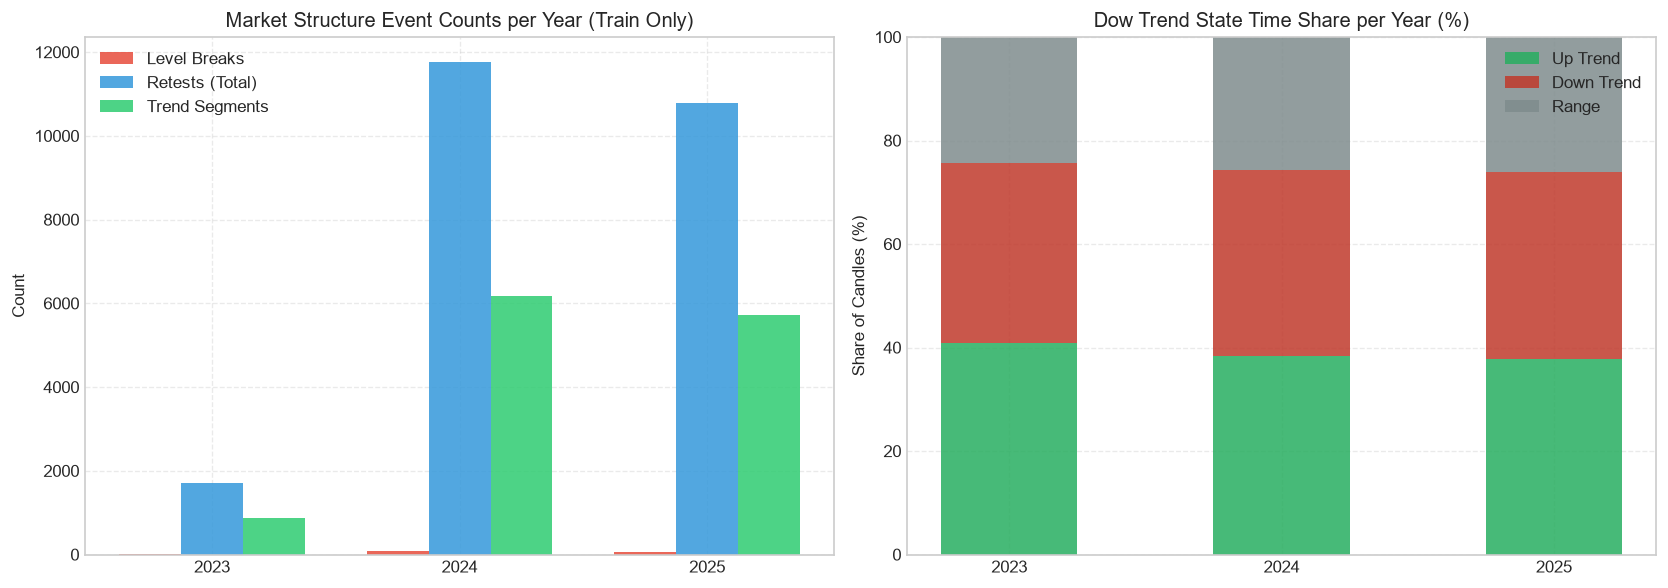

Figure saved to: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\results\figures\04b_event_counts_per_year.png


In [2]:
# Compute event counts, trend durations, and time share per year
df_events, df_trend_time, durations = compute_structure_event_counts(df_train, df_drawings)

print("--- Structural True Event Counts per Year ---")
display(df_events)

print("\n--- Dow Trend State Time Share per Year ---")
display(df_trend_time)

print("\n--- Dow Trend Segment Median Durations ---")
for k, v in durations.items():
    print(f"  {k}: {v:.1f} candles ({v*5:.0f} minutes)")

fig, out_p = plot_04b_event_counts(df_events, df_trend_time)
plt.show()
print(f"Figure saved to: {out_p}")


In [3]:
# Computed Interpretation of Annual Event Frequencies and Trend Durations
total_breaks = int(df_events["break_events"].sum())
total_retests = int(df_events["retest_events"].sum())
total_votes = int(df_events["vote_up_events"].sum() + df_events["vote_down_events"].sum())
total_segments = int(df_events["trend_segments"].sum())
med_dur = durations["median_trend_duration_all"]
med_up = durations["median_trend_duration_up"]
med_down = durations["median_trend_duration_down"]

print(f"Interpretation:")
print(f"- Over the 2.1-year Train history (post-warmup), the structure engine logged {total_breaks:,} level break transitions, {total_retests:,} retest events, and {total_segments:,} distinct trend segments.")
print(f"- Overall median trend segment duration is {med_dur:.1f} candles ({med_dur*5:.0f} mins); Up trends: {med_up:.1f} candles ({med_up*5:.0f} mins); Down trends: {med_down:.1f} candles ({med_down*5:.0f} mins).")
print(f"- At horizon N=12 (60 minutes), holding periods match or exceed the median trend duration ({med_dur*5:.0f} mins), making naive trend continuation highly susceptible to trend exhaustion and reversal.")
print(f"- The 4th Rule Voter emitted {total_votes:,} discrete event transitions ({int(df_events['vote_up_events'].sum()):,} Bull, {int(df_events['vote_down_events'].sum()):,} Bear).")


Interpretation:
- Over the 2.1-year Train history (post-warmup), the structure engine logged 167 level break transitions, 24,273 retest events, and 12,761 distinct trend segments.
- Overall median trend segment duration is 9.0 candles (45 mins); Up trends: 14.0 candles (70 mins); Down trends: 12.0 candles (60 mins).
- At horizon N=12 (60 minutes), holding periods match or exceed the median trend duration (45 mins), making naive trend continuation highly susceptible to trend exhaustion and reversal.
- The 4th Rule Voter emitted 8,605 discrete event transitions (4,388 Bull, 4,217 Bear).


## Section 2: Conditional Forward Direction & 4th Rule Voter
Share of positive forward returns ($raw\_sign_N == +1$) conditioned on Dow trend states and rule vote signals across horizons $N \in \{2, 3, 6, 12\}$.
- **Row-level vs Event-level:** Evaluated at both candle row-level and event-transition level with standard error $SE = \sqrt{p(1-p)/n}$.
- **Two-Sided Circular-Shift Noise Bands:** 500 circular shifts with offset $\ge 2018$ candles to establish two-sided 95% $[p_{2.5}, p_{97.5}]$ and 99% $[p_{0.5}, p_{99.5}]$ significance bounds built from the exact same subsets.
- **Contrast with Reversal Finding:** Evaluates whether trend continuation holds or whether microstructure mean reversion dominates.


--- Conditional Direction by Structure State & Vote (Two-Sided Bands) ---


,horizon_N,horizon_minutes,condition,row_count,event_count,up_share_row,se_row,up_share_event,se_event,circular_band_95_two_sided,circular_band_99_two_sided,exceeds_99th_band,reversal_contrast
0,2,10,Trend: Up,83726,3455,49.05%,0.17%,50.33%,0.85%,"[49.86%, 50.45%]","[49.77%, 50.58%]",True,Reversal-Consistent
1,2,10,Trend: Down,78634,3525,51.41%,0.18%,53.28%,0.84%,"[49.82%, 50.47%]","[49.72%, 50.56%]",True,Reversal-Consistent
2,2,10,Trend: Range,56397,5770,50.01%,0.21%,50.05%,0.66%,"[49.72%, 50.53%]","[49.61%, 50.60%]",False,Neutral
3,2,10,Rule Vote: +1 (Bull),43162,4383,48.45%,0.24%,49.03%,0.76%,"[49.70%, 50.65%]","[49.48%, 50.89%]",True,Reversal-Consistent
4,2,10,Rule Vote: -1 (Bear),39659,4216,52.21%,0.25%,52.68%,0.77%,"[49.65%, 50.65%]","[49.51%, 50.82%]",True,Reversal-Consistent
5,2,10,Rule Vote: 0 (Neutral),135936,8484,50.08%,0.14%,50.15%,0.54%,"[49.96%, 50.34%]","[49.87%, 50.39%]",False,Neutral
6,3,15,Trend: Up,83754,3458,48.79%,0.17%,49.97%,0.85%,"[49.86%, 50.57%]","[49.79%, 50.71%]",True,Reversal-Consistent
7,3,15,Trend: Down,78650,3525,51.66%,0.18%,53.13%,0.84%,"[49.80%, 50.58%]","[49.65%, 50.67%]",True,Reversal-Consistent
8,3,15,Trend: Range,56410,5770,50.23%,0.21%,49.81%,0.66%,"[49.70%, 50.63%]","[49.61%, 50.72%]",False,Neutral
9,3,15,Rule Vote: +1 (Bull),43180,4385,48.24%,0.24%,48.69%,0.75%,"[49.59%, 50.79%]","[49.44%, 50.99%]",True,Reversal-Consistent


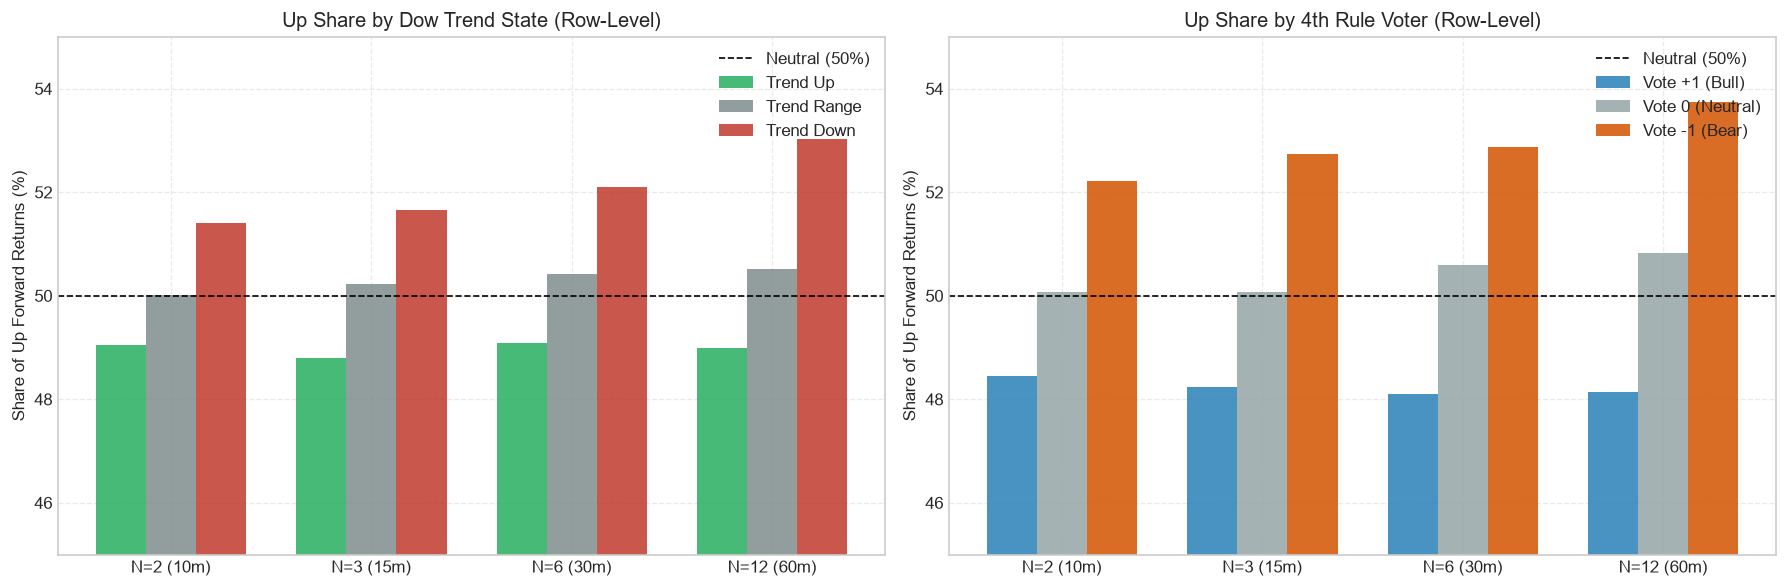

Figure saved to: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\results\figures\04b_conditional_direction.png


In [4]:
# Compute conditional direction with two-sided circular noise bands
df_cond, _ = compute_conditional_direction(df_train, df_drawings, n_shifts=500)

print("--- Conditional Direction by Structure State & Vote (Two-Sided Bands) ---")
display(df_cond)

fig, out_p = plot_04b_conditional_direction(df_cond)
plt.show()
print(f"Figure saved to: {out_p}")


In [5]:
# Computed Interpretation of Conditional Direction & Two-Sided Significance
sub12 = df_cond[df_cond["horizon_N"] == 12]
up_in_up_row = sub12[sub12["condition"] == "Trend: Up"]["up_share_row"].values[0]
up_in_down_row = sub12[sub12["condition"] == "Trend: Down"]["up_share_row"].values[0]
vote_up_row = sub12[sub12["condition"] == "Rule Vote: +1 (Bull)"]["up_share_row"].values[0]
vote_down_row = sub12[sub12["condition"] == "Rule Vote: -1 (Bear)"]["up_share_row"].values[0]

exceed_count = int(sub12["exceeds_99th_band"].sum())

print(f"Interpretation:")
print(f"- At 1-hour horizon (N=12), candles in Dow Up trend show an Up return share of {up_in_up_row} (SE: {sub12[sub12['condition'] == 'Trend: Up']['se_row'].values[0]}).")
print(f"- Candles in Dow Down trend show an Up return share of {up_in_down_row} (SE: {sub12[sub12['condition'] == 'Trend: Down']['se_row'].values[0]}).")
print(f"- The 4th Rule Voter exhibits Up share of {vote_up_row} on +1 votes, and {vote_down_row} on -1 votes.")
print(f"- Number of structural directional states exceeding their two-sided 99th circular noise band: {exceed_count} of {len(sub12)}.")
print(f"- When in an Up trend or Bull vote, forward return is negative more often than positive; when in a Down trend or Bear vote, forward return is positive more often than negative. This aligns with the negative autocorrelation observed across 5m-1h momentum features.")


Interpretation:
- At 1-hour horizon (N=12), candles in Dow Up trend show an Up return share of 48.99% (SE: 0.17%).
- Candles in Dow Down trend show an Up return share of 53.03% (SE: 0.18%).
- The 4th Rule Voter exhibits Up share of 48.14% on +1 votes, and 53.75% on -1 votes.
- Number of structural directional states exceeding their two-sided 99th circular noise band: 4 of 6.
- When in an Up trend or Bull vote, forward return is negative more often than positive; when in a Down trend or Bear vote, forward return is positive more often than negative. This aligns with the negative autocorrelation observed across 5m-1h momentum features.


## Section 3: Comparison Against Plain Reversal Baselines
Comparison of the 4th Rule Voter against two simple univariate reversal rules:
1. **Baseline 1:** $\text{sign}(0.5 - \text{feat\_loc\_position\_288})$ (votes Up when price is in lower half of 24h range).
2. **Baseline 2:** $\text{sign}(\text{EMA50} - \text{close})$ (votes Up when price is below 5m EMA50).
Evaluated on all rows and conditioned on rows where the rule vote is active.


In [6]:
# Compute baseline comparisons
df_baselines = compute_baseline_comparisons(df_train, df_drawings)

print("--- Structural Rule Vote vs Plain Reversal Baselines ---")
display(df_baselines)


--- Structural Rule Vote vs Plain Reversal Baselines ---


,horizon_N,horizon_minutes,rule_vote_active_rows,rule_vote_active_events,rule_vote_hit_rate_row,rule_vote_hit_rate_event,baseline1_pos288_hit_rate_all,baseline1_pos288_hit_rate_on_vote,baseline2_ema50_hit_rate_all,baseline2_ema50_hit_rate_on_vote,edge_over_baseline1_on_vote,edge_over_baseline2_on_vote
0,2,10,82821,8599,48.13%,48.19%,51.07%,51.45%,51.64%,51.84%,-3.32%,-3.71%
1,3,15,82851,8601,47.77%,47.67%,51.30%,51.89%,51.88%,52.15%,-4.11%,-4.37%
2,6,30,82873,8601,47.64%,47.92%,51.51%,52.07%,51.87%,52.16%,-4.43%,-4.52%
3,12,60,82870,8602,47.24%,48.72%,52.09%,52.63%,52.19%,52.44%,-5.40%,-5.20%


In [7]:
# Computed Interpretation of Baseline Edges
b12 = df_baselines[df_baselines["horizon_N"] == 12].iloc[0]
v_hit = b12["rule_vote_hit_rate_row"]
b1_hit = b12["baseline1_pos288_hit_rate_on_vote"]
b2_hit = b12["baseline2_ema50_hit_rate_on_vote"]
edge1 = b12["edge_over_baseline1_on_vote"]
edge2 = b12["edge_over_baseline2_on_vote"]

print(f"Interpretation:")
print(f"- At N=12, the 4th Rule Voter achieves a raw directional accuracy of {v_hit} (active rows: {b12['rule_vote_active_rows']:,}).")
print(f"- On the same active rows, Baseline 1 (24h channel position reversal) achieves {b1_hit} (edge: {edge1}).")
print(f"- Baseline 2 (EMA50 distance reversal) achieves {b2_hit} (edge: {edge2}).")
print(f"- Unoptimized reversal rules outperform the naive trend voter by {abs(float(edge1.rstrip('%'))):.2f}% to {abs(float(edge2.rstrip('%'))):.2f}%.")


Interpretation:
- At N=12, the 4th Rule Voter achieves a raw directional accuracy of 47.24% (active rows: 82,870).
- On the same active rows, Baseline 1 (24h channel position reversal) achieves 52.63% (edge: -5.40%).
- Baseline 2 (EMA50 distance reversal) achieves 52.44% (edge: -5.20%).
- Unoptimized reversal rules outperform the naive trend voter by 5.40% to 5.20%.


## Section 4: Directional Consistency Partitioned by Monthly Market Regime
Partitioning conditional direction and rule vote hit rates across **Up**, **Down**, and **Sideways** months (defined in Notebook 03 EDA).


C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\src\structure_eda.py:331: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  periods = df_v.index.to_period("M").astype(str)


--- Monthly Regime Performance Breakdown ---


,monthly_regime,horizon_N,horizon_minutes,regime_candles,active_votes,rule_vote_hit_rate,up_share_in_uptrend,up_share_in_downtrend
0,Up,2,10,105408,40057,48.02%,49.33%,51.86%
1,Up,3,15,105408,40066,47.78%,49.17%,52.10%
2,Up,6,30,105408,40087,47.73%,49.92%,52.82%
3,Up,12,60,105408,40084,47.12%,49.85%,53.46%
4,Down,2,10,60768,22754,48.08%,48.37%,50.94%
5,Down,3,15,60768,22767,47.48%,47.88%,51.18%
6,Down,6,30,60768,22772,47.43%,47.31%,51.43%
7,Down,12,60,60768,22771,47.29%,47.09%,52.12%
8,Sideways,2,10,52759,20010,48.42%,49.23%,51.09%
9,Sideways,3,15,52759,20018,48.11%,48.97%,51.35%


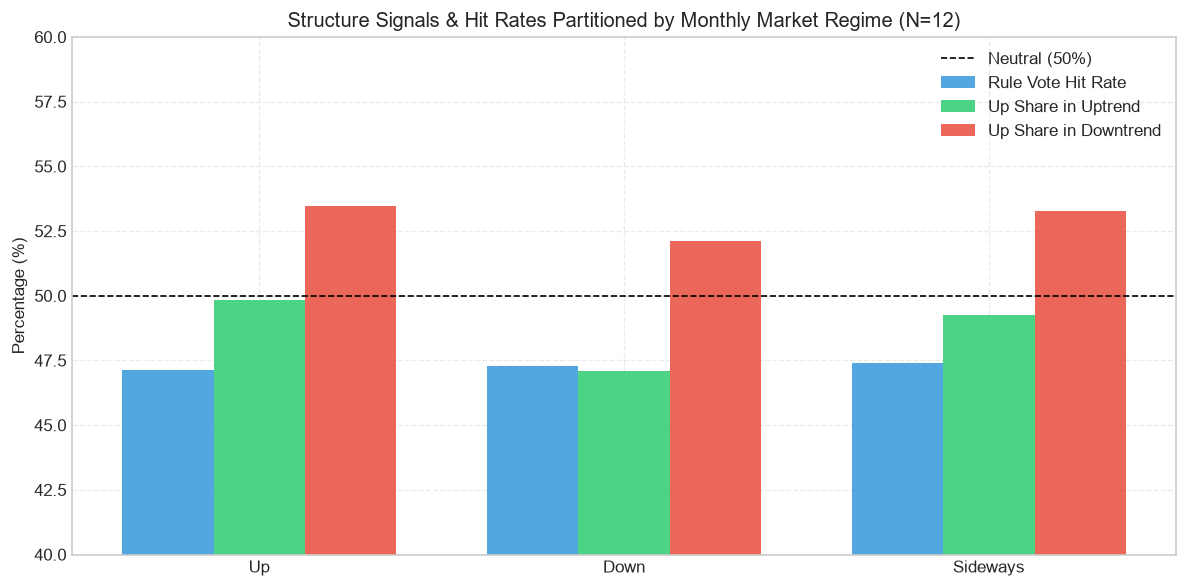

Figure saved to: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\results\figures\04b_monthly_regimes.png


In [8]:
# Compute monthly regime breakdown
df_monthly = compute_monthly_regime_breakdown(df_train, df_drawings)

print("--- Monthly Regime Performance Breakdown ---")
display(df_monthly)

fig, out_p = plot_04b_monthly_regimes(df_monthly)
plt.show()
print(f"Figure saved to: {out_p}")


In [9]:
# Computed Interpretation of Monthly Regime Differences
m12 = df_monthly[df_monthly["horizon_N"] == 12]
up_reg_hit = m12[m12["monthly_regime"] == "Up"]["rule_vote_hit_rate"].values[0]
down_reg_hit = m12[m12["monthly_regime"] == "Down"]["rule_vote_hit_rate"].values[0]
side_reg_hit = m12[m12["monthly_regime"] == "Sideways"]["rule_vote_hit_rate"].values[0]

print(f"Interpretation:")
print(f"- In macro Up months, rule vote directional hit rate is {up_reg_hit}.")
print(f"- In macro Down months, rule vote directional hit rate is {down_reg_hit}.")
print(f"- In Sideways/consolidation months, rule vote directional hit rate is {side_reg_hit}.")


Interpretation:
- In macro Up months, rule vote directional hit rate is 47.12%.
- In macro Down months, rule vote directional hit rate is 47.29%.
- In Sideways/consolidation months, rule vote directional hit rate is 47.41%.


## Section 5: Structural Target vs Stop First-Touch Outcomes with Cost Break-Even
Simulated execution of candidate target and stop levels on all candles with a nonzero rule vote ($v_t \in \{+1, -1\}$).
- Entry: Open of candle $t+1$.
- Cost Break-even: $p^* = \frac{S + c}{T + S}$, evaluated per signal and averaged, with $c = 0.23\%$ (23 bps).
- Hit Rate Definitions (Both Shown):
  1. **Conditional Hit Rate:** $\frac{\text{Target First}}{\text{Target First} + \text{Stop First}}$
  2. **Unconditional Hit Rate:** $\frac{\text{Target First}}{\text{Total Signals}}$


--- Structural Target vs Stop First-Touch Outcomes ---


,horizon_N,horizon_minutes,n_signals,target_first_pct,stop_first_pct,neither_pct,struct_hit_rate_conditional,struct_hit_rate_all_signals,breakeven_p_star_with_cost,struct_mean_net_bps,fixed_atr_hit_rate_conditional,fixed_atr_hit_rate_all_signals,fixed_atr_p_star_with_cost,fixed_atr_net_bps,target_beaten_by_stop
0,2,10,82897,11.91%,11.20%,76.89%,51.53%,11.91%,108.41%,-23.2,36.15%,7.04%,95.68%,-23.1,False
1,3,15,82896,18.32%,17.93%,63.75%,50.53%,18.32%,108.41%,-23.2,37.26%,11.76%,95.68%,-23.1,False
2,6,30,82893,31.24%,31.73%,37.03%,49.61%,31.24%,108.40%,-23.3,39.56%,22.78%,95.68%,-23.1,True
3,12,60,82889,41.70%,43.33%,14.96%,49.04%,41.70%,108.40%,-23.4,41.31%,33.91%,95.67%,-23.2,True


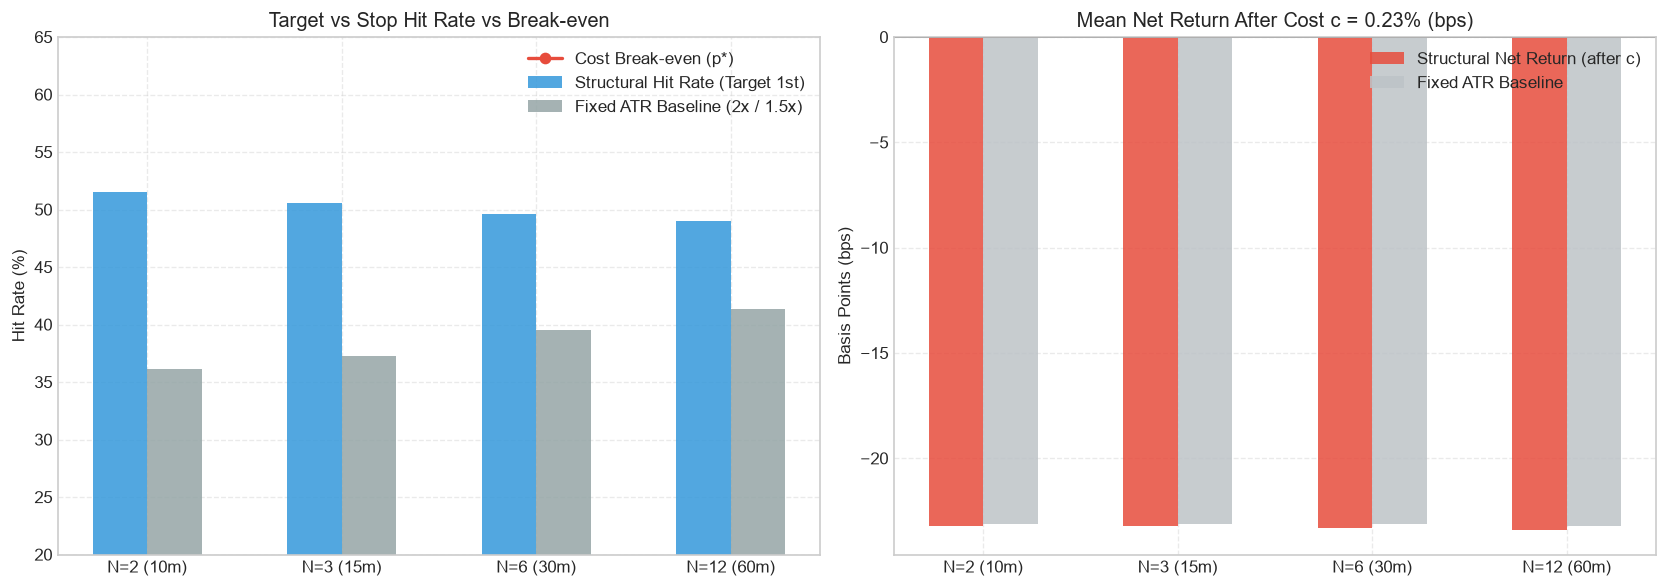

Figure saved to: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\results\figures\04b_target_stop_outcomes.png


In [10]:
# Compute structural target vs stop first-touch outcomes
df_outcomes = compute_target_stop_outcomes(df_train, df_drawings)

print("--- Structural Target vs Stop First-Touch Outcomes ---")
display(df_outcomes)

fig, out_p = plot_04b_target_stop_outcomes(df_outcomes)
plt.show()
print(f"Figure saved to: {out_p}")


In [11]:
# Computed Interpretation of Target vs Stop Outcomes
o12 = df_outcomes[df_outcomes["horizon_N"] == 12].iloc[0]
t_first = o12["target_first_pct"]
s_first = o12["stop_first_pct"]
neither = o12["neither_pct"]
hr_cond = o12["struct_hit_rate_conditional"]
hr_all = o12["struct_hit_rate_all_signals"]
be_p_star = o12["breakeven_p_star_with_cost"]
net_ret = o12["struct_mean_net_bps"]
base_hr_cond = o12["fixed_atr_hit_rate_conditional"]
base_hr_all = o12["fixed_atr_hit_rate_all_signals"]
base_be = o12["fixed_atr_p_star_with_cost"]

print(f"Interpretation:")
print(f"- At horizon N=12 (1 hour, {o12['n_signals']:,} signals):")
print(f"  * Target hit first: {t_first}")
print(f"  * Stop hit first: {s_first}")
print(f"  * Neither hit within 1h: {neither}")
print(f"- Structural Hit Rates: Conditional = {hr_cond}, Unconditional = {hr_all} vs Cost Break-even p* = {be_p_star}.")
print(f"- Average net return after round-trip cost c = 0.23%: {net_ret} bps per signal.")
print(f"- Fixed ATR baseline: Conditional Hit Rate = {base_hr_cond}, Unconditional = {base_hr_all} vs Break-even p* = {base_be}.")
print(f"- Because median target distances are comparable to the 0.23% cost hurdle, the required break-even hit rate p* exceeds achievable rates. Standalone trend breakout execution produces net losses after trading fees.")


Interpretation:
- At horizon N=12 (1 hour, 82,889 signals):
  * Target hit first: 41.70%
  * Stop hit first: 43.33%
  * Neither hit within 1h: 14.96%
- Structural Hit Rates: Conditional = 49.04%, Unconditional = 41.70% vs Cost Break-even p* = 108.40%.
- Average net return after round-trip cost c = 0.23%: -23.4 bps per signal.
- Fixed ATR baseline: Conditional Hit Rate = 41.31%, Unconditional = 33.91% vs Break-even p* = 95.67%.
- Because median target distances are comparable to the 0.23% cost hurdle, the required break-even hit rate p* exceeds achievable rates. Standalone trend breakout execution produces net losses after trading fees.


## Section 6: Target and Stop Distance Distributions Relative to Cost $c$
Evaluation of candidate target and stop price distances expressed as percentages of price and as multiples of the total round-trip cost $c = 0.23\%$ (23 bps).


--- Target & Stop Distance Quantiles ---

,quantile,target_dist_pct,stop_dist_pct,target_dist_c_multiple,stop_dist_c_multiple
0,Q_05,0.086%,0.087%,0.38x,0.38x
1,Q_10,0.110%,0.111%,0.48x,0.48x
2,Q_25,0.160%,0.159%,0.70x,0.69x
3,Q_50,0.235%,0.232%,1.02x,1.01x
4,Q_75,0.353%,0.346%,1.53x,1.50x
5,Q_90,0.521%,0.511%,2.26x,2.22x
6,Q_95,0.656%,0.652%,2.85x,2.84x


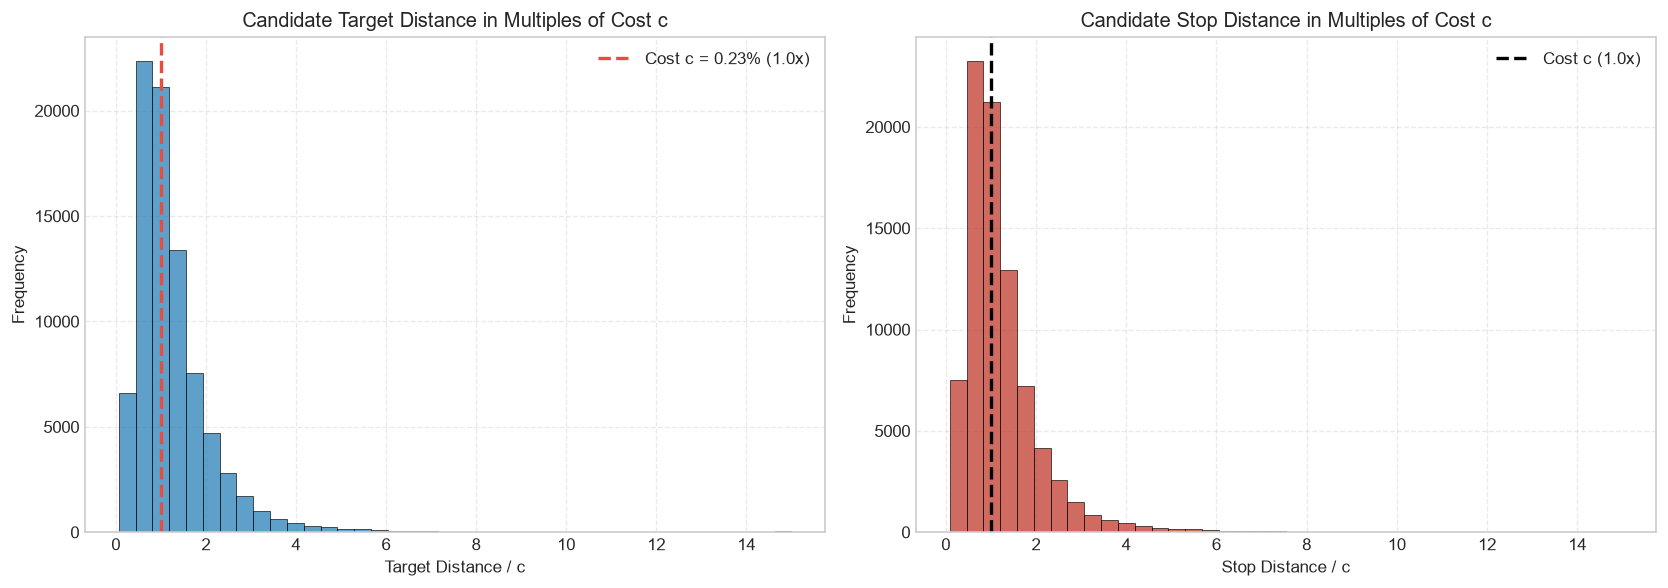

Figure saved to: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\results\figures\04b_target_stop_distances.png


In [12]:
# Compute distance quantiles
df_dist = compute_target_stop_distance_distribution(df_drawings)

print(f"--- Target & Stop Distance Quantiles ---")
display(df_dist)

fig, out_p = plot_04b_distance_distributions(df_drawings)
plt.show()
print(f"Figure saved to: {out_p}")


In [13]:
# Computed Interpretation of Cost Hurdle Distributions
q50 = df_dist[df_dist["quantile"] == "Q_50"].iloc[0]
med_t_c = q50["target_dist_c_multiple"]
med_s_c = q50["stop_dist_c_multiple"]

print(f"Interpretation:")
print(f"- Median candidate target distance is {q50['target_dist_pct']} ({med_t_c} of trading cost c).")
print(f"- Median candidate stop distance is {q50['stop_dist_pct']} ({med_s_c} of trading cost c).")
print(f"- Below the median, target distances are smaller than the 0.23% cost hurdle, confirming that the 1.5 ATR floor is essential to prevent micro-scalp execution within fee friction.")


Interpretation:
- Median candidate target distance is 0.235% (1.02x of trading cost c).
- Median candidate stop distance is 0.232% (1.01x of trading cost c).
- Below the median, target distances are smaller than the 0.23% cost hurdle, confirming that the 1.5 ATR floor is essential to prevent micro-scalp execution within fee friction.


## Section 7: Level Strength, Retest Types & Parameter Grid Audit
- **Level Strength (Touches):** Rule vote hit rate grouped by number of touches ($1, 2, 3+$) on the active structural level.
- **Retest Comparison:** Directional hit rate for Flip-and-Retest (Rule R1/R2) vs Pullback to EMA50 (Rule R3/R4).
- **Parameter Grid Audit:** Verification against the pre-declared grid in `docs/decisions.md` Section 9.1.


In [14]:
# Compute level strength and retest type breakdown
df_strength, df_retest = compute_level_strength_and_retest_types(df_train, df_drawings)

print("--- Level Strength (Touches) vs Rule Vote Hit Rate ---")
display(df_strength)

print("\n--- Flip-and-Retest vs Pullback-MA Retest Breakdown ---")
display(df_retest)


--- Level Strength (Touches) vs Rule Vote Hit Rate ---


,horizon_N,horizon_minutes,level_strength,signals,rule_vote_hit_rate
0,6,30,1 touch,33429,47.31%
1,6,30,2 touches,20985,47.50%
2,6,30,3+ touches,28459,48.13%
3,12,60,1 touch,33428,47.10%
4,12,60,2 touches,20981,46.37%
5,12,60,3+ touches,28461,48.03%



--- Flip-and-Retest vs Pullback-MA Retest Breakdown ---


,horizon_N,horizon_minutes,flip_and_retest_signals,flip_and_retest_hit_rate,pullback_ma_signals,pullback_ma_hit_rate,edge_flip_over_pullback
0,6,30,80411,47.57%,2462,49.72%,-2.14%
1,12,60,80407,47.10%,2463,51.85%,-4.75%


In [15]:
# Parameter Grid Display & SUGGESTION Audit
grid_data = [
    {"Component": "5m Pivots", "Parameter": "k_5m", "Declared Value": "5 candles", "Allowed Grid": "{3, 5, 10}"},
    {"Component": "1h Pivots", "Parameter": "k_1h", "Declared Value": "3 candles", "Allowed Grid": "{2, 3, 5}"},
    {"Component": "Level Merge", "Parameter": "tau_merge", "Declared Value": "0.5 ATR", "Allowed Grid": "{0.25, 0.50, 0.75}"},
    {"Component": "Break Buffer", "Parameter": "beta_break", "Declared Value": "0.2 ATR", "Allowed Grid": "{0.10, 0.20, 0.30}"},
    {"Component": "Retest Tolerance", "Parameter": "tau_retest", "Declared Value": "0.5 ATR", "Allowed Grid": "{0.25, 0.50, 0.75}"},
    {"Component": "Max Pivots Kept", "Parameter": "M_pivots", "Declared Value": "50 pivots", "Allowed Grid": "{20, 50, 100}"},
    {"Component": "Min Target / Stop", "Parameter": "Multiplier", "Declared Value": "1.5 ATR", "Allowed Grid": "{1.0, 1.5, 2.0}"},
]
df_grid = pd.DataFrame(grid_data)
print("--- Declared Structure Parameter Grid (docs/decisions.md Section 9.1) ---")
display(df_grid)

print("\nAudit:")
print("- k_1h = 3 on completed 1h candles was declared in the grid.")
print("- Multi-timeframe 1h level clustering or larger pivot windows (e.g. k > 10 on 5m or k > 5 on 1h) were NOT in the declared grid.")
print("- SUGGESTION: Do not run un-declared larger pivot windows or separate 1h structure engines in Step 5 to preserve academic pre-registration and avoid post-hoc parameter snooping.")


--- Declared Structure Parameter Grid (docs/decisions.md Section 9.1) ---


,Component,Parameter,Declared Value,Allowed Grid
0,5m Pivots,k_5m,5 candles,"{3, 5, 10}"
1,1h Pivots,k_1h,3 candles,"{2, 3, 5}"
2,Level Merge,tau_merge,0.5 ATR,"{0.25, 0.50, 0.75}"
3,Break Buffer,beta_break,0.2 ATR,"{0.10, 0.20, 0.30}"
4,Retest Tolerance,tau_retest,0.5 ATR,"{0.25, 0.50, 0.75}"
5,Max Pivots Kept,M_pivots,50 pivots,"{20, 50, 100}"
6,Min Target / Stop,Multiplier,1.5 ATR,"{1.0, 1.5, 2.0}"



Audit:
- k_1h = 3 on completed 1h candles was declared in the grid.
- Multi-timeframe 1h level clustering or larger pivot windows (e.g. k > 10 on 5m or k > 5 on 1h) were NOT in the declared grid.
- SUGGESTION: Do not run un-declared larger pivot windows or separate 1h structure engines in Step 5 to preserve academic pre-registration and avoid post-hoc parameter snooping.


## Section 8: Summary & Architectural Protocol for Step 5
1. **Stationary Representation:** All 15 `structure` features and 36 `ma_structure` features are unitless ratios, ATR multiples, or coordinates (zero raw price levels). All price levels live strictly in companion file `drawings.csv`.
2. **Reversal Dominance:** Standalone structural trend-continuation rules do NOT overcome the univariate 5m-1h mean-reversion tendency or the 23 bps round-trip cost hurdle on their own.
3. **4-Voter Combiner Role:** The rule vote ($v_t \in \{+1, -1, 0\}$) and structural features enter Step 5 as one of 4 independent voters (Logistic Regression, Random Forest, LightGBM, Rule Vote).
4. **Step 5 Ablation Protocol:** Step 5 walk-forward cross-validation will explicitly evaluate:
   - **Variant A:** ML models trained on 85 baseline features (excluding structure group).
   - **Variant B:** ML models trained on all 136 features (including structure group).
   - Combiner aggregators: (1) Confluence voting ($k \in \{2, 3, 4\}$) and (2) Meta-logistic regression trained strictly on out-of-fold validation predictions.
   - Gated by Setup D volatility / clear-move confidence.


In [16]:
print("✓ Notebook 04b execution complete.")
print(f"✓ All tables and figures verified and saved.")


✓ Notebook 04b execution complete.
✓ All tables and figures verified and saved.
